# IndoBERT Clickbait Detection - Complete Pipeline

This notebook runs the complete training and evaluation pipeline for IndoBERT-based clickbait detection with robustness evaluation.

**Requirements:**
- GPU Runtime (T4 for testing, A100 for full training)
- 5 CSV files with columns: `id`, `source`, `date`, `title`, `Label`, `url`
  (one file per domain: technology.csv, politic.csv, health.csv, sport.csv, education.csv)
- ~(TBA) hours for complete execution

❗❗**BOLD -> changed**

---
**model: large**

**BertTokenizer**

DROPOUT_RATE: float = 0.1

# Hyperparameters
LEARNING_RATE: float = 2e-5

BATCH_SIZE: int = 32

NUM_EPOCHS: int = 4

WEIGHT_DECAY: float = 0.01

WARMUP_RATIO: float = 0.1

# Optimizer
OPTIMIZER: str = "AdamW"

EPSILON: float = 1e-8

MAX_GRAD_NORM: float = 1.0

# Early stopping
EARLY_STOPPING_PATIENCE: int = 2

EARLY_STOPPING_METRIC: str = "f1"

# Learning rate scheduler
SCHEDULER_TYPE: str = "linear"

In [ ]:
from IPython.display import HTML, display
import base64
import math
import struct
import wave
import io

def play_sound():
    sample_rate = 44100
    duration = 3.0
    beep_duration = 0.3
    beep_interval = 0.45
    frequency = 1200
    volume = 0.4

    buffer = io.BytesIO()

    with wave.open(buffer, "wb") as wav:
        wav.setnchannels(1)
        wav.setsampwidth(2)
        wav.setframerate(sample_rate)

        samples = []

        for i in range(int(sample_rate * duration)):
            t = i / sample_rate

            # Determine whether we're inside a beep
            cycle = t % beep_interval

            if cycle < beep_duration:
                # Smooth fade in/out
                fade = min(
                    1.0,
                    cycle / 0.02,
                    (beep_duration - cycle) / 0.02
                )

                value = (
                    volume
                    * fade
                    * math.sin(2 * math.pi * frequency * t)
                )
            else:
                value = 0

            samples.append(struct.pack("<h", int(value * 32767)))

        wav.writeframes(b"".join(samples))

    audio_base64 = base64.b64encode(buffer.getvalue()).decode()

    display(HTML(f"""
        <audio autoplay>
            <source src="data:audio/wav;base64,{audio_base64}" type="audio/wav">
        </audio>
    """))

In [ ]:
import zipfile
import os

zip_path = "/content/ths_test.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Rename extracted folder
os.rename(
    "/content/ths_test",
    "/content/domain-shift-trustworthy-ai"
)

In [ ]:
import os

os.environ["HF_HUB_DISABLE_XET"] = "1"

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# %cd /content
# !rm -rf domain-shift-trustworthy-ai

%cd /content/drive/MyDrive/
!rm -rf run_thesis

%cd /content
!rm -rf checkpoints_staging

%cd domain-shift-trustworthy-ai

/content/drive/MyDrive
/content
/content/domain-shift-trustworthy-ai


## 1. Environment Setup

In [ ]:
# Check GPU availability
!nvidia-smi

Tue Oct 20 01:48:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# # Clone repository or upload code files
# # Option 1: Clone from GitHub
# !git clone https://github.com/gredss/domain-shift-trustworthy-ai.git
# %cd domain-shift-trustworthy-ai

# # # Option 2: Upload files manually
# # from google.colab import files
# # import os

# # print("Upload all Python files (.py) from your project")
# # uploaded = files.upload()

# # # List uploaded files
# # !ls -lh *.py

Cloning into 'domain-shift-trustworthy-ai'...
remote: Enumerating objects: 596, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 596 (delta 13), reused 33 (delta 9), pack-reused 549 (from 1)
Receiving objects: 100% (596/596), 8.42 MiB | 10.74 MiB/s, done.
Resolving deltas: 100% (348/348), done.
/content/domain-shift-trustworthy-ai/domain-shift-trustworthy-ai


In [ ]:
path = "/content/domain-shift-trustworthy-ai/src/evaluation_engine.py"
with open(path, "r", encoding="utf-8") as f:
    content = f.read()
# Convert every tab character to 4 spaces
content = content.expandtabs(4)
with open(path, "w", encoding="utf-8") as f:
    f.write(content)
print("Converted all tabs to 4 spaces.")
#CHECK ========================================================
!python -m py_compile /content/domain-shift-trustworthy-ai/src/evaluation_engine.py

##############################
path = "/content/domain-shift-trustworthy-ai/src/evaluate_pipeline.py"
with open(path, "r", encoding="utf-8") as f:
    content = f.read()
# Convert every tab character to 4 spaces
content = content.expandtabs(4)
with open(path, "w", encoding="utf-8") as f:
    f.write(content)
print("Converted all tabs to 4 spaces.")
#CHECK ========================================================
!python -m py_compile /content/domain-shift-trustworthy-ai/src/evaluate_pipeline.py

###############
path = "/content/domain-shift-trustworthy-ai/src/perturbation_engine.py"
with open(path, "r", encoding="utf-8") as f:
    content = f.read()
# Convert every tab character to 4 spaces
content = content.expandtabs(4)
with open(path, "w", encoding="utf-8") as f:
    f.write(content)
print("Converted all tabs to 4 spaces.")
#CHECK ========================================================
!python -m py_compile /content/domain-shift-trustworthy-ai/src/perturbation_engine.py

Converted all tabs to 4 spaces.
Converted all tabs to 4 spaces.
Converted all tabs to 4 spaces.


In [ ]:
# Install dependencies
!pip install -q torch transformers pandas numpy scikit-learn scipy streamlit plotly tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 112.6 MB/s eta 0:00:00


## 2. Data Preparation

In [ ]:
# Create necessary directories
!mkdir -p dataset
!mkdir -p /content/drive/MyDrive/thesis/checkpoints
!mkdir -p /content/drive/MyDrive/thesis/results
!mkdir -p /content/drive/MyDrive/thesis/outputs

In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/domain-shift-trustworthy-ai/dataset/data")

# Verify the files exist
csv_files = list(DATA_DIR.glob("*.csv"))
print(csv_files)

[PosixPath('/content/domain-shift-trustworthy-ai/dataset/data/politic.csv'), PosixPath('/content/domain-shift-trustworthy-ai/dataset/data/education.csv'), PosixPath('/content/domain-shift-trustworthy-ai/dataset/data/technology.csv'), PosixPath('/content/domain-shift-trustworthy-ai/dataset/data/health.csv'), PosixPath('/content/domain-shift-trustworthy-ai/dataset/data/sport.csv')]


In [ ]:
# ── DATA SANITY CHECK: per-domain CSV row counts and label balance ──────────
# Reads the raw CSV files only. No data is modified here.
import pandas as pd
import glob
import os

csv_files = sorted(
    glob.glob('/content/domain-shift-trustworthy-ai/dataset/data/*.csv')
)
print(f"Found {len(csv_files)} CSV files\n")

# Build one summary row per file so we can print a clean aligned table.
summary_rows = []
for csv_file in csv_files:
    df = pd.read_csv(csv_file, sep=';')
    label_counts = df['Label'].value_counts().to_dict()
    n_non = int(label_counts.get(0, 0))   # 0 = non-clickbait
    n_click = int(label_counts.get(1, 0))  # 1 = clickbait
    total = len(df)
    summary_rows.append({
        "file": os.path.basename(csv_file),
        "rows": total,
        "non_clickbait": n_non,
        "clickbait": n_click,
        "clickbait_ratio": (n_click / total) if total else 0.0,
    })

# Print an aligned table.
print(f"{'File':<20}{'Rows':>7}{'Non-CB':>9}{'CB':>7}{'CB ratio':>10}")
print("-" * 53)
for r in summary_rows:
    print(
        f"{r['file']:<20}"
        f"{r['rows']:>7}"
        f"{r['non_clickbait']:>9}"
        f"{r['clickbait']:>7}"
        f"{r['clickbait_ratio']:>10.3f}"
    )

# Totals row.
total_rows = sum(r['rows'] for r in summary_rows)
total_non = sum(r['non_clickbait'] for r in summary_rows)
total_click = sum(r['clickbait'] for r in summary_rows)
print("-" * 53)
print(
    f"{'TOTAL':<20}"
    f"{total_rows:>7}"
    f"{total_non:>9}"
    f"{total_click:>7}"
    f"{(total_click / total_rows if total_rows else 0):>10.3f}"
)

Found 5 CSV files

File                   Rows   Non-CB     CB  CB ratio
-----------------------------------------------------
education.csv          1000      666    334     0.334
health.csv             1000      438    562     0.562
politic.csv            1000      903     97     0.097
sport.csv              1000      903     97     0.097
technology.csv         1000      795    205     0.205
-----------------------------------------------------
TOTAL                  5000     3705   1295     0.259


In [ ]:
# # Quick data verification from the existing dataset/data folder CSV files
# import pandas as pd
# import glob

# csv_files = glob.glob('dataset/data/*.csv')
# print(f"Found {len(csv_files)} CSV files\n")

# for csv_file in csv_files:
#     df = pd.read_csv(csv_file, sep=';')
#     print(f"{csv_file}:")
#     print(f"  Rows: {len(df)}")
#     print(f"  Columns: {list(df.columns)}")
#     print(f"  Label distribution: {df['Label'].value_counts().to_dict()}")
#     print()

## 3. Model Training

Train IndoBERT models.

In [ ]:
# %cd domain-shift-trustworthy-ai

# Train large model (recommended for initial testing)
# Trains one specialist model per domain (5 specialists x 1 variant = 5 models)
!python src/train_pipeline.py \
    --model base \
    --dataset-dir dataset/data \
    --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
    --output-dir /content/drive/MyDrive/thesis/outputs \
    --device cuda \
    --seed 42 \
    --debug #\
    #--grid-search

# !python src/train_pipeline.py \
#     --model base \
#     --dataset-dir /content/domain-shift-trustworthy-ai/dataset/data \
#     --checkpoint-dir "/content/drive/MyDrive/BINUS/Prethesis and Thesis/experiment/checkpoints" \
#     --output-dir "/content/drive/MyDrive/BINUS/Prethesis and Thesis/experiment/output" \
#     --device cuda \
#     --seed 42 \
#     --debug

2026-10-20 01:51:06,646 - INFO - [debug_logger] Debug output ENABLED for this run
2026-10-20 01:51:06,779 - INFO - Training Pipeline initialized
2026-10-20 01:51:06,779 - INFO - Dataset: dataset/data, Output: /content/drive/MyDrive/thesis/outputs, Checkpoints: /content/drive/MyDrive/thesis/checkpoints
2026-10-20 01:51:06,779 - INFO - Device: cuda, Random seed: 42
2026-10-20 01:51:06,779 - INFO - 
Starting SPECIALIST Training Pipeline
2026-10-20 01:51:06,779 - INFO - 
[STEP 1] Loading and Preparing Data
2026-10-20 01:51:06,779 - INFO - DataManager initialized with seed=42, max_length=128
2026-10-20 01:51:06,779 - INFO - Loading 5 CSV files

[DataManager] ──── Data quality check  →  Technology ───────────────────────────
    null_titles: 0
    short_titles: 0
    long_titles: 0
    duplicate_titles: 0
2026-10-20 01:51:06,790 - INFO - Loaded 1000 samples from technology.csv (domain: Technology)

[DataManager] ──── CSV loaded  →  domain=Technology ────────────────────────────
    file     

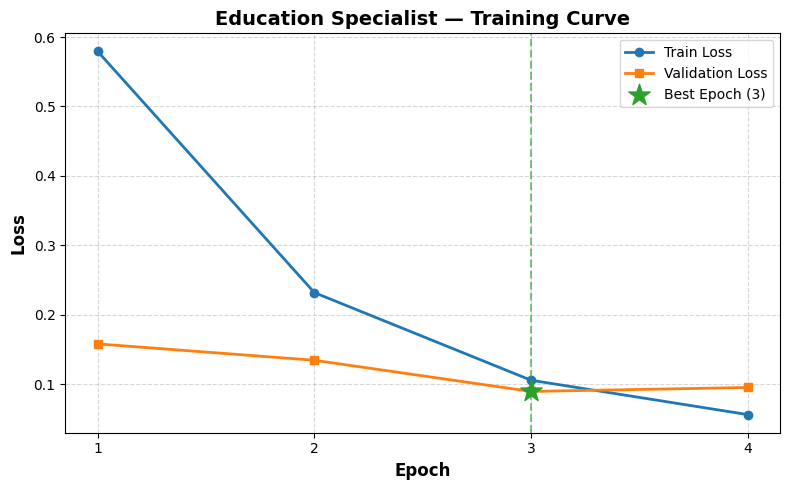

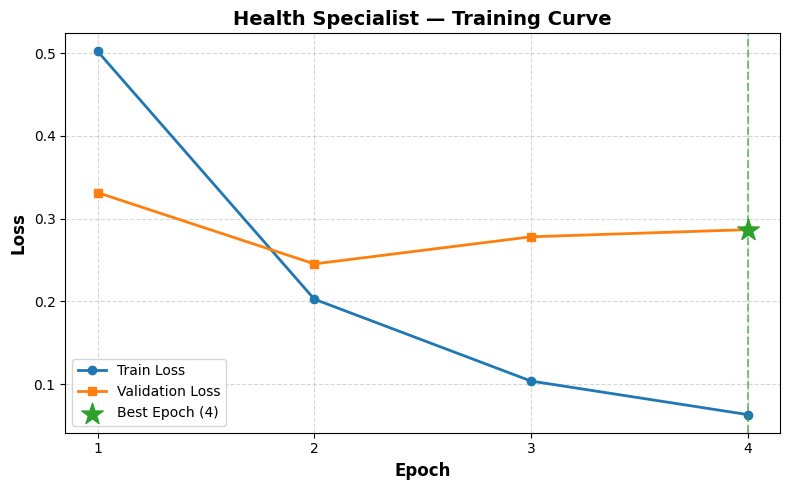

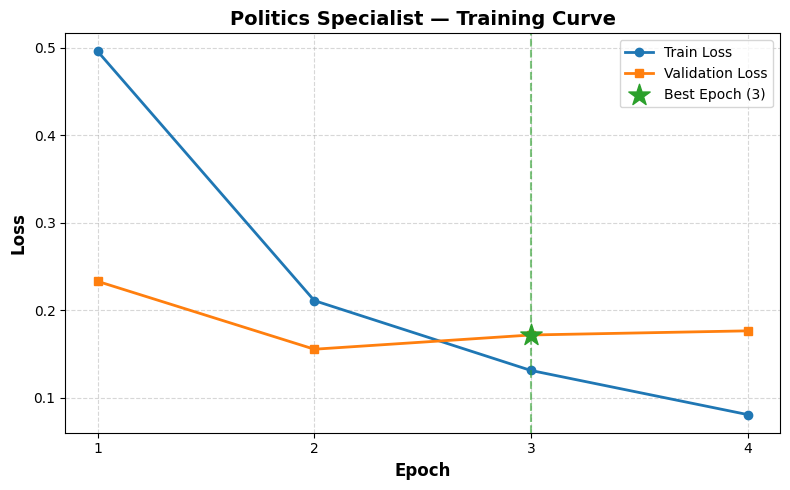

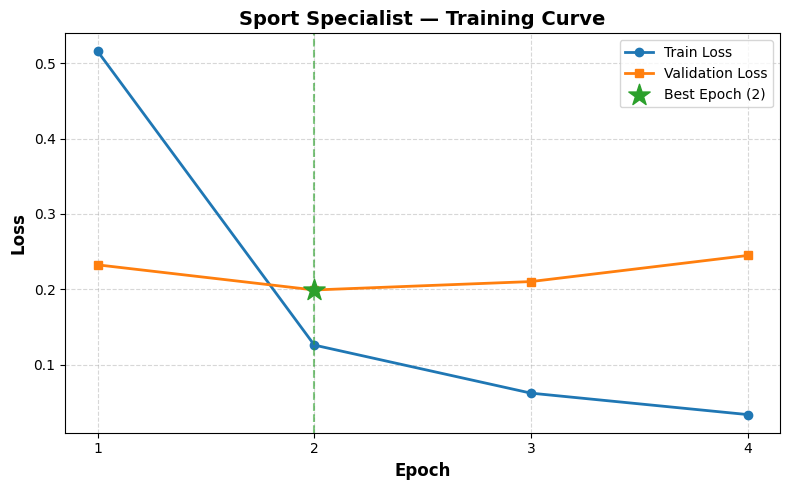

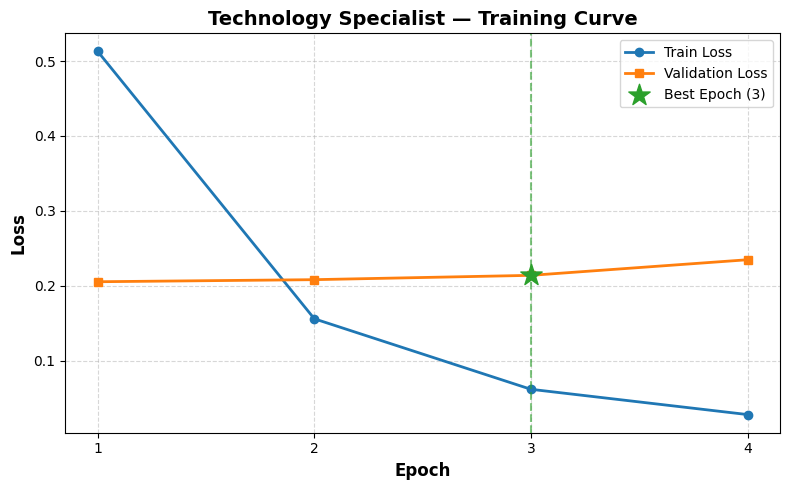

In [ ]:
# ── TRAINING CURVES: train vs. validation loss per domain specialist ────────
# Reads the saved training_history.json files only. Training itself is done in
# the pipeline cell above; nothing here changes the model or its training.
import json
import os
import matplotlib.pyplot as plt

CKPT_ROOT = "/content/drive/MyDrive/thesis/checkpoints/base"
DOMAINS = ["Education", "Health", "Politics", "Sport", "Technology"]

for domain in DOMAINS:
    history_path = os.path.join(CKPT_ROOT, domain, "training_history.json")
    with open(history_path, "r") as f:
        history = json.load(f)

    epochs = history["epochs"]
    train_loss = history["train_loss"]
    val_loss = history["val_loss"]
    val_macro_f1 = history["val_macro_f1"]

    # Best epoch = the one with the highest validation Macro-F1.
    best_idx = val_macro_f1.index(max(val_macro_f1))
    best_epoch = epochs[best_idx]
    best_val_loss = val_loss[best_idx]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs, train_loss, marker="o", linewidth=2,
            color="tab:blue", label="Train Loss")
    ax.plot(epochs, val_loss, marker="s", linewidth=2,
            color="tab:orange", label="Validation Loss")

    # Mark the best epoch clearly.
    ax.scatter([best_epoch], [best_val_loss], marker="*", s=260,
               color="tab:green", zorder=5,
               label=f"Best Epoch ({best_epoch})")
    ax.axvline(best_epoch, linestyle="--", linewidth=1.5,
               color="tab:green", alpha=0.6)

    ax.set_title(f"{domain} Specialist — Training Curve",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=12, fontweight="bold")
    ax.set_ylabel("Loss", fontsize=12, fontweight="bold")
    ax.set_xticks(epochs)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


In [ ]:
# ── CHECKPOINT SANITY CHECK: does each domain specialist exist? ─────────────
import os

CKPT_ROOT = "/content/drive/MyDrive/thesis/checkpoints/base"
DOMAINS = ["Education", "Health", "Politics", "Sport", "Technology"]

print(f"{'Domain':<14}{'Checkpoint found':>18}")
print("-" * 32)
all_present = True
for domain in DOMAINS:
    ckpt = os.path.join(CKPT_ROOT, domain, "best_model.pt")
    present = os.path.exists(ckpt)
    all_present = all_present and present
    status = "yes" if present else "MISSING"
    print(f"{domain:<14}{status:>18}")
print("-" * 32)
print("All specialists present." if all_present
      else "WARNING: at least one specialist checkpoint is missing.")


Domain          Checkpoint found
--------------------------------
Education                    yes
Health                       yes
Politics                     yes
Sport                        yes
Technology                   yes
--------------------------------
All specialists present.


In [ ]:
# Train all models (base, large, large) - Use A100 GPU for this
# Uncomment to run:
# !python src/train_pipeline.py \
#     --model all \
#     --dataset-dir dataset \
#     --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
#     --output-dir /content/drive/MyDrive/thesis/output \
#     --device cuda \
#     --seed 42

In [ ]:
# Optional: Train with hyperparameter grid search
# !python src/train_pipeline.py \
#     --model base \
#     --dataset-dir dataset \
#     --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
#     --output-dir /content/drive/MyDrive/thesis/output \
#     --device cuda \
#     --grid-search \
#     --seed 42

## 4. Model Evaluation

Run comprehensive evaluation including in-domain, cross-domain, and perturbation testing.

In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.9 MB/s eta 0:00:00


**USE HIGHEST CONTEXTUAL SIMILARITY**

```
best = max(
          candidates,
          key=lambda x: x["similarity"],
      )
```



In [ ]:
# %cd domain-shift-trustworthy-ai

# Evaluate large model with full perturbation testing
# --train-output-dir must match --output-dir used in train_pipeline.py
# so evaluation reuses the exact same test splits the model never saw during training.
!python src/evaluate_pipeline.py \
    --model base \
    --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
    --dataset-dir dataset/data \
    --output-dir /content/drive/MyDrive/thesis/results \
    --train-output-dir /content/drive/MyDrive/thesis/outputs/ \
    --device cuda \
    --seed 42 \
    --debug \
    2>&1 | tee /content/drive/MyDrive/thesis/results/evaluation_full.log


# play_sound()

Output streaming akan dipotong hingga 5000 baris terakhir.
  sample [0]  label=non-clickbait
    original   : Kisah Zahira, Putri Pedagang Kelontong-Difabel Daksa Kuliah di Unesa Lewat KIP Kuliah
    input_ids  : [2, 2959, 17684, 1473, 30468, 3466, 4793, 241, 2375, 30365] … (total=128, real=22)
    attn_mask  : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] … (n_pad=106)
    decoded    : [CLS] kisah zahira, putri pedagang kelontong - difabel daksa kuliah di unesa lewat kip kuliah [SEP]
  sample [1]  label=non-clickbait
    original   : Takut Gagal Bikin Bisnis Gak Jalan-jalan? Temukan Solusinya di Tingkat Ini
    input_ids  : [2, 2790, 3588, 2999, 996, 1489, 795, 30469, 795, 30477] … (total=128, real=16)
    attn_mask  : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] … (n_pad=112)
    decoded    : [CLS] takut gagal bikin bisnis gak jalan - jalan? temukan solusinya di tingkat ini [SEP]
Predicting:   0%|          | 0/5 [00:00<?, ?it/s]
[ModelTrainer] ──── Predict  batch 0 ────────────────────────────────────────────
  

In [ ]:
import os
import pandas as pd

# ============================================================
# CONFIG
# ============================================================
BASE_DIR = "/content/drive/MyDrive/thesis/results/base"
DOMAINS = ["education", "health", "politics", "sport", "technology"]
LEVELS = ["low", "medium", "high"]

# This thesis evaluates the SYNONYM (semantic) perturbation only.
# The per-domain CSVs live at: <BASE_DIR>/<domain>/semantic/<level>.csv
PERTURBATION_TYPE = "semantic"


# ============================================================
# LOAD DATA (one domain at a time, synonym perturbation)
# ============================================================
def load_domain_data(domain):
    domain_dir = os.path.join(BASE_DIR, domain, PERTURBATION_TYPE)
    level_to_dataframe = {}
    for level in LEVELS:
        path = os.path.join(domain_dir, f"{level}.csv")
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing file: {path}")
        dataframe = pd.read_csv(path)
        if "id" in dataframe.columns:
            dataframe = dataframe.set_index("id")
        level_to_dataframe[level] = dataframe
    return level_to_dataframe


# ============================================================
# CLASSIFY TEXT PATTERN (exact string equality)
# ============================================================
def classify_perturbation(low_row, medium_row, high_row):
    low_success = bool(low_row["perturbation_in_range"])
    medium_success = bool(medium_row["perturbation_in_range"])
    high_success = bool(high_row["perturbation_in_range"])

    # A sample is only classified when all three levels hit their target range.
    if not (low_success and medium_success and high_success):
        return None

    low_text = str(low_row["perturbed_text"])
    medium_text = str(medium_row["perturbed_text"])
    high_text = str(high_row["perturbed_text"])

    low_equals_medium = low_text == medium_text
    low_equals_high = low_text == high_text
    medium_equals_high = medium_text == high_text

    if low_equals_medium and medium_equals_high:
        return "Low = Medium = High"
    if medium_equals_high and not low_equals_medium:
        return "Medium = High != Low"
    if low_equals_medium and not low_equals_high:
        return "Low = Medium != High"
    if low_equals_high and not low_equals_medium:
        return "Low = High != Medium"
    return "Low != Medium != High"


# ============================================================
# ANALYZE ONE DOMAIN
# ============================================================
def analyze_domain(domain):
    level_to_dataframe = load_domain_data(domain)
    low_df = level_to_dataframe["low"]
    medium_df = level_to_dataframe["medium"]
    high_df = level_to_dataframe["high"]

    common_ids = (
        low_df.index
        .intersection(medium_df.index)
        .intersection(high_df.index)
    )
    if len(common_ids) == 0:
        raise ValueError(f"No common samples found for domain: {domain}")

    results = []
    for sample_id in common_ids:
        low_row = low_df.loc[sample_id]
        medium_row = medium_df.loc[sample_id]
        high_row = high_df.loc[sample_id]
        results.append({
            "id": sample_id,
            "low_success": bool(low_row["perturbation_in_range"]),
            "medium_success": bool(medium_row["perturbation_in_range"]),
            "high_success": bool(high_row["perturbation_in_range"]),
            "pattern": classify_perturbation(low_row, medium_row, high_row),
        })
    return pd.DataFrame(results)


# ============================================================
# RUN (synonym perturbation only)
# ============================================================
print("#" * 80)
print("#  PERTURBATION TYPE: SEMANTIC (synonym substitution)")
print("#" * 80)

all_details = {}
all_summaries = []
for domain in DOMAINS:
    detail_df = analyze_domain(domain)
    all_details[domain] = detail_df
    all_summaries.append({
        "domain": domain,
        "total_samples": len(detail_df),
        "low_success": int(detail_df["low_success"].sum()),
        "low_failed": int((~detail_df["low_success"]).sum()),
        "medium_success": int(detail_df["medium_success"].sum()),
        "medium_failed": int((~detail_df["medium_success"]).sum()),
        "high_success": int(detail_df["high_success"].sum()),
        "high_failed": int((~detail_df["high_success"]).sum()),
    })

summary_df = pd.DataFrame(all_summaries)

# ---- Success / failed per level ----
print("\n" + "=" * 80)
print("SUCCESS / FAILURE BY LEVEL  (semantic)")
print("=" * 80)
for level in LEVELS:
    print("\n" + "-" * 51)
    print(f"{level.upper()} LEVEL")
    print("-" * 51)
    success_col = f"{level}_success"
    failed_col = f"{level}_failed"
    print(f"{'Domain':<15}{'Success':>12}{'Failed':>12}{'Total':>12}")
    print("-" * 51)
    for _, row in summary_df.iterrows():
        print(
            f"{row['domain'].upper():<15}"
            f"{row[success_col]:>12}"
            f"{row[failed_col]:>12}"
            f"{row['total_samples']:>12}"
        )
    print("-" * 51)
    print(
        f"{'TOTAL':<15}"
        f"{summary_df[success_col].sum():>12}"
        f"{summary_df[failed_col].sum():>12}"
        f"{summary_df['total_samples'].sum():>12}"
    )

# ---- Text patterns per domain ----
print("\n" + "=" * 80)
print("PERTURBATION PATTERNS BY DOMAIN  (semantic)")
print("=" * 80)
for domain, detail_df in all_details.items():
    counts = detail_df["pattern"].value_counts()
    failed_count = (
        (~detail_df["low_success"])
        | (~detail_df["medium_success"])
        | (~detail_df["high_success"])
    ).sum()
    print("\n" + "-" * 80)
    print(f"DOMAIN: {domain.upper()}")
    print("-" * 80)
    print(f"Failed:                 {failed_count}")
    print(f"Low = Medium = High:    {counts.get('Low = Medium = High', 0)}")
    print(f"Medium = High != Low:   {counts.get('Medium = High != Low', 0)}")
    print(f"Low = Medium != High:   {counts.get('Low = Medium != High', 0)}")
    print(f"Low = High != Medium:   {counts.get('Low = High != Medium', 0)}")
    print(f"Low != Medium != High:  {counts.get('Low != Medium != High', 0)}")

# ---- Final table ----
print("\n" + "=" * 80)
print("FINAL SUMMARY TABLE  (semantic)")
print("=" * 80)
print(summary_df.to_string(index=False))


In [ ]:
# -- QUICK PEEK: one perturbed result for the synonym mechanism, to confirm
# the nested JSON structure.
# Structure: results["perturbation"][domain]["clean" | "semantic"][level]
import json

PERTURB_LEVELS = ["low", "medium", "high"]

path = "/content/drive/MyDrive/thesis/results/base/complete_evaluation.json"
with open(path, "r", encoding="utf-8") as f:
    results = json.load(f)

# Show the first domain, first level of the semantic mechanism as a check.
first_domain = next(iter(results["perturbation"]))
domain_block = results["perturbation"][first_domain]
print("DOMAIN:", first_domain)
print("Top-level keys:", list(domain_block.keys()))  # expect: clean, semantic

level = PERTURB_LEVELS[0]
result = domain_block["semantic"][level]
print(f"\n--- SEMANTIC / {level.upper()} ---")
print("Macro-F1:", result["metrics"]["macro_f1"])
print("Similarity:",
      result["perturbation_statistics"]["semantic_similarity"])
print("Flip:", result.get("prediction_flip", {}).get("flip_rate_pct"))


In [ ]:
import os

# ============================================================
# CONFIG
# ============================================================

PROJECT_ROOT = "/content/drive/MyDrive/thesis"
MODEL = "base"

# Core directories
RESULTS_ROOT = os.path.join(PROJECT_ROOT, "results")
OUTPUTS_ROOT = os.path.join(PROJECT_ROOT, "outputs")

# Model-specific directories
RESULTS_DIR = os.path.join(RESULTS_ROOT, MODEL)
OUTPUT_DIR = os.path.join(OUTPUTS_ROOT, MODEL, "evaluation_results")

# Files
COMPLETE_EVALUATION_JSON = os.path.join(
    RESULTS_DIR,
    "complete_evaluation.json"
)

CROSS_DOMAIN_PERTURBATION_JSON = os.path.join(
    RESULTS_DIR,
    "cross_domain_perturbation_results.json"
)

EVALUATION_SUMMARY_JSON = os.path.join(
    RESULTS_ROOT,
    "evaluation_summary.json"
)

TRAINING_SUMMARY_JSON = os.path.join(
    OUTPUTS_ROOT,
    "training_summary.json"
)

# Data splits
SPLITS_DIR = os.path.join(
    OUTPUTS_ROOT,
    "data_splits"
)

# Domains / perturbation
DOMAINS = [
    "Education",
    "Health",
    "Politics",
    "Sport",
    "Technology"
]

PERTURB_LEVELS = [
    "clean",
    "low",
    "medium",
    "high"
]

# Metrics
METRICS_TO_PLOT = {
    "macro_f1": "Macro-F1",
    "f1_0": "F1₀ (Non-Clickbait)",
    "f1_1": "F1₁ (Clickbait)"
}

**testing prediction flip**

In [ ]:
# -- PREDICTION FLIP ANALYSIS --------------------------------------------
# How often does a synonym perturbation flip the predicted label? We compute
# this per domain, per level, from the nested results.
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

with open(COMPLETE_EVALUATION_JSON, "r", encoding="utf-8") as f:
    results = json.load(f)

PERTURB_LEVELS = ["low", "medium", "high"]

# ---- Flatten the nested flip data into one tidy DataFrame ---------------
rows = []
for domain, domain_block in results["perturbation"].items():
    for level in PERTURB_LEVELS:
        level_block = domain_block.get("semantic", {}).get(level)
        if level_block is None:
            continue
        flip = level_block.get("prediction_flip", {})
        rows.append({
            "domain": domain,
            "level": level,
            "flip_rate_pct": flip.get("flip_rate_pct", 0),
            "flip_0_to_1_count": flip.get("flip_0_to_1_count", 0),
            "flip_1_to_0_count": flip.get("flip_1_to_0_count", 0),
            "correct_to_incorrect":
                flip.get("flips", {}).get("correct_to_incorrect", 0),
            "incorrect_to_correct":
                flip.get("flips", {}).get("incorrect_to_correct", 0),
        })

df = pd.DataFrame(rows)

# ---- Print the full flip table -------------------------------------------
print("=" * 80)
print("PREDICTION FLIP ANALYSIS  (synonym; per domain / level)")
print("=" * 80)
print(df.to_string(index=False))

# ---- Average flip rate by level ------------------------------------------
print("\n" + "=" * 80)
print("AVERAGE FLIP RATE (%) BY LEVEL")
print("=" * 80)
average_flip_by_level = (
    df.groupby("level")["flip_rate_pct"].mean().reindex(PERTURB_LEVELS)
)
print(average_flip_by_level.round(2).to_string())

# ---- Chart: flip rate vs. intensity, one line per domain -----------------
x_base = np.arange(len(PERTURB_LEVELS))
fig, ax = plt.subplots(figsize=(9, 6))
for domain in df["domain"].unique():
    domain_rows = (
        df[df["domain"] == domain]
        .set_index("level")
        .reindex(PERTURB_LEVELS)
    )
    ax.plot(x_base, domain_rows["flip_rate_pct"].values,
            marker="o", linewidth=2, label=domain)
ax.set_title("Prediction Flip Rate Across Synonym Perturbation Intensities",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Perturbation Level", fontsize=12, fontweight="bold")
ax.set_ylabel("Prediction Flip Rate (%)", fontsize=12, fontweight="bold")
ax.set_xticks(x_base)
ax.set_xticklabels([level.capitalize() for level in PERTURB_LEVELS])
ax.grid(True, alpha=0.3)
ax.legend(title="Domain", bbox_to_anchor=(1.01, 0.5), loc="center left",
          frameon=True)
fig.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
# -- FLIP AMONG SUCCESSFUL PERTURBATIONS ONLY (synonym) ------------------
# "Successful" = the perturbation actually changed the text within range.
PERTURB_LEVELS = ["low", "medium", "high"]

for domain, domain_block in results["perturbation"].items():
    print("\n" + "=" * 80)
    print(domain.upper())
    print("=" * 80)
    print("  SEMANTIC")
    for level in PERTURB_LEVELS:
        level_block = domain_block.get("semantic", {}).get(level)
        if level_block is None:
            continue
        flip = level_block.get("prediction_flip", {})
        print(f"    {level.capitalize():<8} "
              f"successful={flip.get('successful_perturbations')}  "
              f"flips(successful-only)={flip.get('flip_count_successful_only')}  "
              f"rate={flip.get('flip_rate_successful_only_pct')}%")


In [ ]:
# Quick evaluation (skip perturbation testing for faster results)
# !python src/evaluate_pipeline.py \
#     --model base \
#     --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
#     --dataset-dir dataset/data \
#     --output-dir /content/drive/MyDrive/thesis/results \
#     --train-output-dir /content/drive/MyDrive/thesis/output \
#     --device cuda \
#     --skip-perturbation \
#     --seed 42

In [ ]:
# Evaluate all models (if you trained all)
# !python src/evaluate_pipeline.py \
#     --model all \
#     --checkpoint-dir /content/drive/MyDrive/thesis/checkpoints \
#     --dataset-dir dataset/data \
#     --output-dir /content/drive/MyDrive/thesis/results \
#     --train-output-dir /content/drive/MyDrive/thesis/output \
#     --device cuda \
#     --seed 42

## **Perturbation Check**

In [ ]:
# # -- INPUT: clean test text  |  OUTPUT: perturbed text (synonym mechanism) --
# import sys
# sys.path.insert(0, "/content/domain-shift-trustworthy-ai/src")
# import pandas as pd
# from perturbation_engine import PerturbationEngine

# engine = PerturbationEngine(thesaurus_path="/content/dict.json", random_seed=42)

# # Pick 3 samples from the Technology test split for a concrete demonstration.
# test_df = pd.read_csv(f"{SPLITS_DIR}/technology/test.csv")
# samples = test_df.sample(n=3, random_state=0)["text"].tolist()

# # The synonym (semantic) mechanism uses the level names: low / medium / high.
# LEVELS = ["low", "medium", "high"]


# def change_ratio(original, perturbed):
#     """Simple character-change ratio, just for a quick visual sanity check."""
#     changed = 0
#     for original_char, perturbed_char in zip(original, perturbed):
#         if original_char != perturbed_char:
#             changed = changed + 1
#     return changed / max(len(original), 1)


# SEP = "=" * 80
# for sample_index, original in enumerate(samples):
#     print(f"\n{SEP}")
#     print(f"Sample {sample_index + 1}")
#     print(SEP)
#     print(f"  ORIGINAL : {original}")
#     print("\n  --- SEMANTIC (synonym substitution) ---")
#     for label, engine_level in zip(["LOW", "MEDIUM", "HIGH"], LEVELS):
#         perturbed = engine.apply_perturbation(original, engine_level)
#         print(f"  {label:<7}: {perturbed}")
#         print(f"           char-change = {change_ratio(original, perturbed):.1%}")
# print(SEP)


**Perturbation Intensity Validation**

In [ ]:
import os
import numpy as np
import pandas as pd

# ============================================================
# CONFIG
# ============================================================
BASE_DIR = "/content/drive/MyDrive/thesis/results/base"
DOMAINS = ["education", "health", "politics", "sport", "technology"]
LEVELS = ["low", "medium", "high"]

# Synonym (semantic) mechanism only: <domain>/semantic/<level>.csv
PERTURBATION_TYPE = "semantic"


# ============================================================
# WORD-LEVEL CHANGE (the natural unit for the SEMANTIC mechanism)
# ============================================================
def calculate_word_changes(original, perturbed):
    """Count changed words by position. Example:
        original  = "A B C D"
        perturbed = "A X C Y"  -> 2 changed / 4 = 0.50
    """
    original_words = str(original).split()
    perturbed_words = str(perturbed).split()
    original_count = len(original_words)
    if original_count == 0:
        return 0.0
    max_len = max(len(original_words), len(perturbed_words))
    changed = 0
    for i in range(max_len):
        if i >= len(original_words):
            changed = changed + 1
        elif i >= len(perturbed_words):
            changed = changed + 1
        elif original_words[i] != perturbed_words[i]:
            changed = changed + 1
    return changed / original_count


# ============================================================
# ACHIEVED INTENSITY for one file (word-change ratio).
# ============================================================
def analyze_file(path, domain, level):
    df = pd.read_csv(path)

    if "perturbation_in_range" not in df.columns:
        raise ValueError(f"{path} missing 'perturbation_in_range'")

    achieved_ratios = []
    for _, row in df.iterrows():
        achieved_ratios.append(
            calculate_word_changes(row["original_text"], row["perturbed_text"])
        )
    df["achieved_ratio"] = achieved_ratios
    unit = "word-change ratio"

    successful = df["perturbation_in_range"].astype(bool)
    successful_ratios = df.loc[successful, "achieved_ratio"]

    total = len(df)
    n_success = int(successful.sum())
    summary = {
        "domain": domain.capitalize(),
        "level": level.capitalize(),
        "unit": unit,
        "total_samples": total,
        "successful_samples": n_success,
        "success_rate": (n_success / total) if total else 0.0,
        "mean_achieved_ratio": (successful_ratios.mean() if n_success else np.nan),
        "median_achieved_ratio": (successful_ratios.median() if n_success else np.nan),
        "min_achieved_ratio": (successful_ratios.min() if n_success else np.nan),
        "max_achieved_ratio": (successful_ratios.max() if n_success else np.nan),
    }
    return summary, df


# ============================================================
# RUN (synonym perturbation only)
# ============================================================
print("#" * 80)
print("#  ACTUAL PERTURBATION INTENSITY: SEMANTIC (synonym substitution)")
print("#" * 80)

summaries = []
for domain in DOMAINS:
    for level in LEVELS:
        path = os.path.join(BASE_DIR, domain, PERTURBATION_TYPE, f"{level}.csv")
        if not os.path.exists(path):
            print(f"WARNING: File not found: {path}")
            continue
        summary, _ = analyze_file(path, domain, level)
        summaries.append(summary)
        print(f"Loaded {domain:<12} {level:<7} {summary['total_samples']} samples")

summary_df = pd.DataFrame(summaries)

# ---- Intensity summary table ----
print("\n" + "=" * 90)
print(f"ACHIEVED INTENSITY SUMMARY  (semantic; unit = {summary_df['unit'].iloc[0]})")
print("=" * 90)
show_cols = [
    "domain", "level", "total_samples", "successful_samples",
    "success_rate", "mean_achieved_ratio", "median_achieved_ratio",
    "min_achieved_ratio", "max_achieved_ratio",
]
print(summary_df[show_cols].to_string(index=False,
                                      float_format=lambda x: f"{x:.4f}"))

# ---- Intensity order check: Low < Medium < High (mean achieved ratio) ----
print("\n" + "=" * 90)
print("INTENSITY CHECK: LOW < MEDIUM < HIGH  (semantic)")
print("=" * 90)
intensity = summary_df.pivot(
    index="domain", columns="level", values="mean_achieved_ratio"
)
for col in ["Low", "Medium", "High"]:
    if col not in intensity.columns:
        intensity[col] = np.nan
intensity = intensity[["Low", "Medium", "High"]]
intensity["Low < Medium < High"] = (
    (intensity["Low"] < intensity["Medium"])
    & (intensity["Medium"] < intensity["High"])
)
print(intensity.to_string(float_format=lambda x: f"{x:.4f}"))


## **Inspect In-Domain Evaluation — Inputs and Outputs**

Loads the saved evaluation results and shows, for each domain specialist:
the test texts going in, the predicted labels coming out, and the per-domain metrics.

In [ ]:
# ── INPUT: test texts + true labels  |  OUTPUT: predictions + metrics ─────────
import json, pandas as pd


# RESULTS_DIR = "/content/drive/MyDrive/thesis/results/base"
# SPLITS_DIR  = "/content/drive/MyDrive/thesis/outputs/data_splits"

with open(COMPLETE_EVALUATION_JSON, "r") as f:
    ev = json.load(f)

SEP = "─" * 80
print("IN-DOMAIN EVALUATION — inputs and predicted outputs")
print(SEP)
print(f"{'Domain':<14} {'N':>5}  {'Acc':>7}  {'MacroF1':>8}  {'F1-CB':>7}  {'FP':>5}  {'FN':>5}")
print(SEP)

for domain, data in ev["in_domain"].items():
    m  = data["metrics"]
    cm = m.get("confusion_matrix", [[0,0],[0,0]])
    print(f"{domain:<14} {data['num_samples']:>5}  "
          f"{m['accuracy']:>7.4f}  {m['macro_f1']:>8.4f}  "
          f"{m.get('f1_1', m.get('f1_1', 0)):>7.4f}  "
          f"{cm[0][1]:>5}  {cm[1][0]:>5}")

# Show 4 concrete prediction examples for Education
print(f"\n── Sample predictions: Education specialist on Education test set ──")
edu_test = pd.read_csv(f"{SPLITS_DIR}/education/test.csv")
edu_data = ev["in_domain"].get("Education", {})
preds    = edu_data.get("predictions", [])
trues    = edu_data.get("true_labels", [])
texts    = edu_test["text"].tolist()

print(f"  {'True':>13}  {'Pred':>13}  Text")
print(f"  {'─'*13}  {'─'*13}  {'─'*50}")
count = 0
for txt, true, pred in zip(texts, trues, preds):
    label_t = "clickbait" if true == 1 else "non-clickbait"
    label_p = "clickbait" if pred == 1 else "non-clickbait"
    mark = "  ✗" if true != pred else ""
    print(f"  {label_t:>13}  {label_p:>13}  {str(txt)[:60]}{mark}")
    count += 1
    if count >= 6:
        break

IN-DOMAIN EVALUATION — inputs and predicted outputs
────────────────────────────────────────────────────────────────────────────────
Domain             N      Acc   MacroF1    F1-CB     FP     FN
────────────────────────────────────────────────────────────────────────────────
Education        150   0.9267    0.9162   0.8866      4      7
Health           150   0.9067    0.9053   0.9167      7      7
Politics         150   0.9800    0.9427   0.8966      1      2
Sport            150   0.9733    0.9212   0.8571      1      3
Technology       150   0.9400    0.9096   0.8571      5      4

── Sample predictions: Education specialist on Education test set ──
           True           Pred  Text
  ─────────────  ─────────────  ──────────────────────────────────────────────────
  non-clickbait  non-clickbait  Kisah Zahira, Putri Penjual Kelontong-Difabel Daksa Kuliah d
      clickbait      clickbait  Takut Gagal Bikin Bisnis Gak Jalan-jalan? Temukan Solusinya 
  non-clickbait  non-clickbait  

## **Inspect Cross-Domain Evaluation — Source Model on Target Texts**

Shows which source-domain specialist was used, what target-domain texts it received,
and how its predictions compare to the target specialist's in-domain performance.

In [ ]:
# ── INPUT: source specialist + target test texts  |  OUTPUT: metrics + shift ──
import json
import pandas as pd

with open(COMPLETE_EVALUATION_JSON, "r") as f:
    ev = json.load(f)

# Define the domains list explicitly
domains = ["Education", "Health", "Politics", "Sport", "Technology"]

# ── Cross-domain performance matrix ──
cd = ev["cross_domain"]

print("CROSS-DOMAIN Macro-F1  (row = source specialist, col = target test set)")
print(f"{'Source':<12}", end="")
for d in domains:
    print(f"  {d[:9]:>9}", end="")
print()
print("-" * 65)
for src in domains:
    print(f"{src:<12}", end="")
    for tgt in domains:
        key = f"{src}->{tgt}"
        f1  = cd.get(key, {}).get("metrics", {}).get("macro_f1", 0.0)
        marker = "*" if src == tgt else " "
        print(f"  {f1:>8.4f}{marker}", end="")
    print()

# ── Concrete example: Technology specialist predicting Health test set ──
print("\n── Example: Technology specialist applied to Health test texts ──")
key = "Technology->Health"
cd_data = cd.get(key, {})
preds   = cd_data.get("predictions", [])
trues   = cd_data.get("true_labels", [])
shift   = cd_data.get("domain_shift", {})

health_test = pd.read_csv(f"{SPLITS_DIR}/health/test.csv")
texts       = health_test["text"].tolist()

mf1_src = ev["in_domain"].get("Technology", {}).get("metrics", {}).get("macro_f1", 0)
mf1_tgt = ev["in_domain"].get("Health",     {}).get("metrics", {}).get("macro_f1", 0)
mf1_cd  = cd_data.get("metrics", {}).get("macro_f1", 0)
print(f"  Technology in-domain F1 : {mf1_src:.4f}")
print(f"  Health in-domain F1     : {mf1_tgt:.4f}")
print(f"  Technology→Health F1    : {mf1_cd:.4f}")
print(f"  Source Drop (SD)        : {shift.get('sd_macro_f1', 0):+.4f}")
print(f"  Target Drop (TD)        : {shift.get('td_macro_f1', 0):+.4f}")

print(f"\n  {'True':>13}  {'Pred':>13}  Health headline")
print(f"  {'─'*13}  {'─'*13}  {'─'*50}")
count = 0
for txt, true, pred in zip(texts, trues, preds):
    label_t = "clickbait" if true == 1 else "non-clickbait"
    label_p = "clickbait" if pred == 1 else "non-clickbait"
    mark = "  ✗" if true != pred else ""
    print(f"  {label_t:>13}  {label_p:>13}  {str(txt)[:55]}{mark}")
    count += 1
    if count >= 6:
        break

CROSS-DOMAIN Macro-F1  (row = source specialist, col = target test set)
Source        Education     Health   Politics      Sport  Technolog
-----------------------------------------------------------------
Education       0.9162*    0.8655     0.9158     0.8036     0.9051 
Health          0.8675     0.9053*    0.9630     0.6707     0.8723 
Politics        0.7976     0.7788     0.9427*    0.7900     0.8809 
Sport           0.8392     0.8199     0.9158     0.9212*    0.8958 
Technology      0.8675     0.8527     0.9158     0.8352     0.9096*

── Example: Technology specialist applied to Health test texts ──
  Technology in-domain F1 : 0.9096
  Health in-domain F1     : 0.9053
  Technology→Health F1    : 0.8527
  Source Drop (SD)        : +0.0569
  Target Drop (TD)        : +0.0526

           True           Pred  Health headline
  ─────────────  ─────────────  ──────────────────────────────────────────────────
  non-clickbait  non-clickbait  Masih Beredar Luas, Galon Guna Ulang Tua Bisa 

## 5. View Results

In [ ]:
# Print evaluation summary + error analysis
# --results-dir must point to the model subfolder (results/base, results/large, etc.)
# because evaluate_pipeline.py saves complete_evaluation.json inside results/{model}/
!python src/print_evaluation_summary.py \
    --results-dir /content/drive/MyDrive/thesis/results/ \
    --model base


════════════════════════════════════════════════════════════════════════════════
════════════════════════════════════════════════════════════════════════════════
                        EVALUATION SUMMARY  ·  MODEL: BASE
════════════════════════════════════════════════════════════════════════════════
════════════════════════════════════════════════════════════════════════════════

════════════════════════════════════════════════════════════════════════════════
══════════════ 1. IN-DOMAIN PERFORMANCE (Specialist → Own Domain) ══════════════
════════════════════════════════════════════════════════════════════════════════
Domain           Accuracy   Macro_F1Macro-PrecisionMacro-Recall        MCC    ROC-AUC
────────────────────────────────────────────────────────────────────────────────
Education          0.9267     0.9162     0.9235     0.9100     0.8334     0.9792
Health             0.9067     0.9053     0.9053     0.9053     0.8106     0.9692
Politics           0.9800     0.9427     0.

In [ ]:
# ── CHECKPOINT FILE SIZES: confirm saved specialists on Drive and local ─────
from pathlib import Path

DOMAINS = ["Education", "Health", "Politics", "Sport", "Technology"]

def list_checkpoint_sizes(root_dir, label):
    print(f"\n{label}")
    print(f"  root: {root_dir}")
    root = Path(root_dir)
    for domain in DOMAINS:
        domain_dir = root / domain
        print(f"  {domain}")
        if not domain_dir.exists():
            print("    (directory not found)")
            continue
        for f in sorted(domain_dir.iterdir()):
            size_mb = f.stat().st_size / 1024 ** 2
            print(f"    {f.name:<24} {size_mb:>8.2f} MB")

list_checkpoint_sizes(
    "/content/drive/MyDrive/thesis/checkpoints/base",
    "DRIVE checkpoints (final destination)",
)
list_checkpoint_sizes(
    "/content/checkpoints_staging/base",
    "LOCAL staging checkpoints (before Drive copy)",
)



DRIVE checkpoints (final destination)
  root: /content/drive/MyDrive/thesis/checkpoints/base
  Education
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB
  Health
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB
  Politics
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB
  Sport
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB
  Technology
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB

LOCAL staging checkpoints (before Drive copy)
  root: /content/checkpoints_staging/base
  Education
    best_model.pt             1419.87 MB
    best_model_history.json      0.00 MB
    training_history.json        0.00 MB
  Health
    b

In [ ]:
# -- RESULT TABLES: in-domain, cross-domain, and perturbation (synonym) --
import json

with open(COMPLETE_EVALUATION_JSON, "r") as f:
    data = json.load(f)

DOMAINS = list(data["in_domain"].keys())
PERTURB_LEVELS = ["low", "medium", "high"]
PERTURB_SEQUENCE = ["clean", "low", "medium", "high"]


def clean_metric(domain, metric):
    """Shared clean baseline for a domain (falls back to in-domain)."""
    clean = (
        data["perturbation"].get(domain, {})
        .get("clean", {}).get("metrics", {}).get(metric)
    )
    if clean is None:
        clean = data["in_domain"].get(domain, {}).get("metrics", {}).get(metric, 0)
    return clean


def pert_metric(domain, level, metric):
    """One perturbed (synonym) metric from the nested structure (0 if missing)."""
    return (
        data["perturbation"].get(domain, {})
        .get("semantic", {}).get(level, {})
        .get("metrics", {}).get(metric, 0)
    )


# ---- 1. IN-DOMAIN --------------------------------------------------------
print("=" * 65)
print("  1. IN-DOMAIN - F1 per Class")
print("=" * 65)
print(f"{'Domain':<14} {'F1_0':>8} {'F1_1':>8} {'Macro_F1':>10}")
print("-" * 65)
for domain in DOMAINS:
    m = data["in_domain"][domain]["metrics"]
    print(f"{domain:<14} {m['f1_0']:>8.4f} {m['f1_1']:>8.4f} {m['macro_f1']:>10.4f}")

# ---- 2. CROSS-DOMAIN MATRICES -------------------------------------------
def print_cross_matrix(metric_key, title):
    print("\n" + "=" * 65)
    print(f"  2. CROSS-DOMAIN - {title} (Row=Source, Col=Target)")
    print("=" * 65)
    header = f"{'Source':<14}" + "".join(f"{d[:6]:>10}" for d in DOMAINS)
    print(header)
    print("-" * 65)
    for src in DOMAINS:
        row = f"{src:<14}"
        for tgt in DOMAINS:
            key = f"{src}->{tgt}"
            entry = data["cross_domain"].get(key, {})
            if "metrics" in entry:
                marker = "*" if src == tgt else " "
                row += f"{entry['metrics'][metric_key]:>9.4f}{marker}"
            else:
                row += f"{'N/A':>10}"
        print(row)
    print("  (* = in-domain diagonal, shown for reference)")

print_cross_matrix("f1_0", "F1_0 Matrix")
print_cross_matrix("f1_1", "F1_1 Matrix")

# ---- 3. PERTURBATION (synonym) ------------------------------------------
print("\n" + "=" * 65)
print("  3. PERTURBATION (synonym) - F1_0 / F1_1 / Macro-F1 per Domain per Level")
print("=" * 65)
for domain in DOMAINS:
    print(f"\n  [{domain}]")
    print(f"    {'Level':<10} {'F1_0':>8} {'F1_1':>8} {'Macro_F1':>10}")
    print(f"    {'-' * 38}")
    for level in PERTURB_SEQUENCE:
        if level == "clean":
            f1_0 = clean_metric(domain, "f1_0")
            f1_1 = clean_metric(domain, "f1_1")
            macro = clean_metric(domain, "macro_f1")
        else:
            f1_0 = pert_metric(domain, level, "f1_0")
            f1_1 = pert_metric(domain, level, "f1_1")
            macro = pert_metric(domain, level, "macro_f1")
        print(f"    {level.capitalize():<10} {f1_0:>8.4f} {f1_1:>8.4f} {macro:>10.4f}")


In [ ]:
# -- PERTURBATION LINE CHARTS (synonym) ----------------------------------
# For each metric we draw one chart with the 5 domain lines across
# Clean -> Low -> Medium -> High. The Clean point is the unperturbed baseline.
import matplotlib.pyplot as plt
import numpy as np

# (Assumes DOMAINS, PERTURB_LEVELS, PERTURB_SEQUENCE, clean_metric() and
#  pert_metric() from the table cell above.)

metrics_to_plot = {
    "macro_f1": "Macro-F1",
    "f1_0": "F1_0 (Non-Clickbait)",
    "f1_1": "F1_1 (Clickbait)",
}

x_labels = [level.capitalize() for level in PERTURB_SEQUENCE]
x_base = np.arange(len(PERTURB_SEQUENCE))
offsets = np.linspace(-0.06, 0.06, len(DOMAINS))

for metric_key, metric_name in metrics_to_plot.items():
    fig, ax = plt.subplots(figsize=(9, 6))

    for idx, domain in enumerate(DOMAINS):
        clean = clean_metric(domain, metric_key)
        values = [clean]
        for level in PERTURB_LEVELS:
            values.append(pert_metric(domain, level, metric_key))
        ax.plot(x_base + offsets[idx], values,
                marker="o", linewidth=2, alpha=0.85, label=domain)

    ax.set_title(f"{metric_name} Across Synonym Perturbation Levels",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Perturbation Level", fontsize=12, fontweight="bold")
    ax.set_ylabel(metric_name, fontsize=12, fontweight="bold")
    ax.set_xticks(x_base)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.3)
    ax.legend(title="Domain", bbox_to_anchor=(1.01, 0.5), loc="center left",
              frameon=True)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


In [ ]:
# -- CROSS-DOMAIN PERTURBATION TABLES (synonym) --------------------------
# Structure: results["cross_domain_perturbation"][pair] = {
#     "clean": {...}, "semantic": {low, medium, high} }
# We build one tidy DataFrame then print Macro-F1 tables per source domain.
import json
import pandas as pd

with open(COMPLETE_EVALUATION_JSON, "r") as f:
    data = json.load(f)

DOMAINS = list(data["in_domain"].keys())
PERTURB_LEVELS = ["low", "medium", "high"]

cross_results = data["cross_domain_perturbation"]
print(f"Number of source-target pairs: {len(cross_results)}")

rows = []
for pair, conditions in cross_results.items():
    source, target = pair.split("_to_", 1)

    # Shared clean baseline.
    clean_macro = conditions.get("clean", {}).get("metrics", {}).get("macro_f1")

    semantic_block = conditions.get("semantic", {})
    for level in PERTURB_LEVELS:
        level_block = semantic_block.get(level)
        if level_block is None:
            continue
        m = level_block["metrics"]
        rows.append({
            "source_domain": source.strip(),
            "target_domain": target.strip(),
            "level": level,
            "macro_f1": m["macro_f1"],
            "clean_macro_f1": clean_macro,
        })

df = pd.DataFrame(rows)

# Print a Macro-F1 table per source domain: rows=target, cols=level.
print("\n" + "#" * 80)
print(f"CROSS-DOMAIN PERTURBATION (synonym) - MACRO-F1 - {MODEL.upper()}")
print("#" * 80)
for source_domain in DOMAINS:
    sub = df[df["source_domain"] == source_domain]
    if sub.empty:
        continue
    table = (
        sub.pivot(index="target_domain", columns="level", values="macro_f1")
           .reindex(index=DOMAINS, columns=PERTURB_LEVELS)
    )
    formatted = table.map(lambda x: f"{x:.4f}" if pd.notna(x) else "-")
    print("\n" + "=" * 80)
    print(f"TRAIN DOMAIN: {source_domain.upper()}")
    print("=" * 80)
    print(formatted.to_string())

# Overall average Macro-F1 by level.
print("\n" + "=" * 80)
print("OVERALL CROSS-DOMAIN PERTURBATION (mean Macro-F1 by level)")
print("=" * 80)
overall = df.groupby("level")["macro_f1"].mean().reindex(PERTURB_LEVELS)
print(overall.round(4).to_string())


In [ ]:
# View training summary
# training_summary.json structure:
#   training_results -> {model_name -> {domain_name -> {best_f1, checkpoint_dir, ...}}}
import json

with open(TRAINING_SUMMARY_JSON, "r") as f:
    training_summary = json.load(f)

print("Training Summary:")
print(f"Total samples: {training_summary['total_samples']}")
print(f"Domains: {', '.join(training_summary['domains'])}")
print(f"\nBest F1 Scores per model per domain:")
for model_name, domain_results in training_summary['training_results'].items():
    print(f"  {model_name.upper()}:")
    for domain_name, info in domain_results.items():
        print(f"    {domain_name}: {info['best_macro_f1']:.4f}")

Training Summary:
Total samples: 5000
Domains: Education, Health, Politics, Sport, Technology

Best F1 Scores per model per domain:
  BASE:
    Education: 0.9550
    Health: 0.9056
    Politics: 0.8528
    Sport: 0.8038
    Technology: 0.9074


In [ ]:
# -- EVALUATION SUMMARY: per-model averages (synonym) --------------------
import json

with open(EVALUATION_SUMMARY_JSON, "r") as f:
    eval_summary = json.load(f)

print("Evaluation Summary")
print("=" * 50)
for model, metrics in eval_summary["model_summaries"].items():
    print(f"\n{model.upper()}")
    print(f"  Avg In-Domain Macro-F1   : {metrics['avg_in_domain_f1']:.4f}")
    print(f"  Avg Cross-Domain Macro-F1: {metrics['avg_cross_domain_f1']:.4f}")
    # Perturbation average (synonym mechanism).
    if "avg_perturbation_f1" in metrics:
        print(f"  Avg Perturbation Macro-F1: {metrics['avg_perturbation_f1']:.4f}")


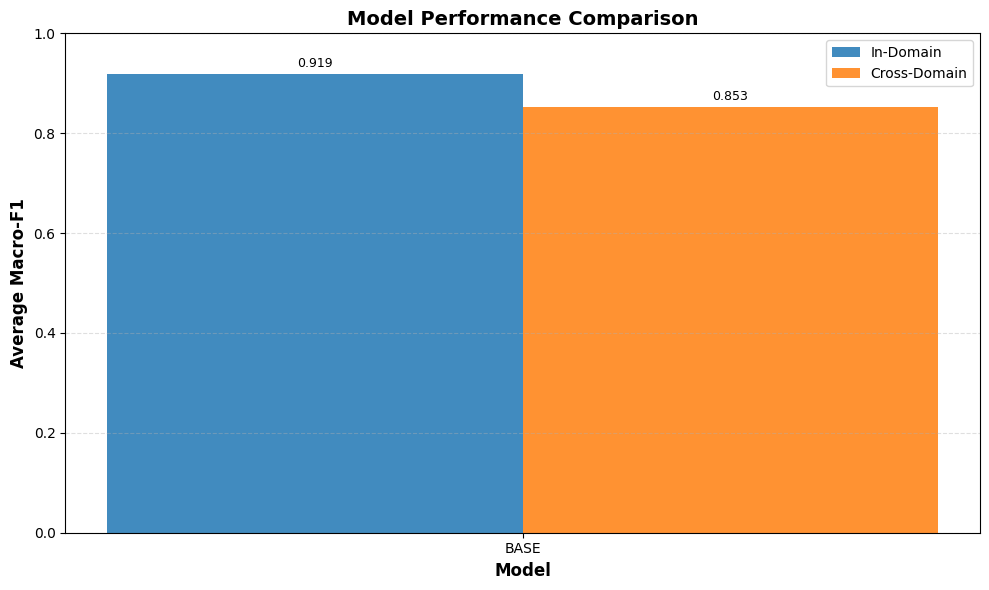

In [ ]:
# ── MODEL PERFORMANCE COMPARISON: in-domain vs cross-domain (avg Macro-F1) ──
import matplotlib.pyplot as plt
import numpy as np

models = list(eval_summary["model_summaries"].keys())
in_domain_f1 = [eval_summary["model_summaries"][m]["avg_in_domain_f1"] for m in models]
cross_domain_f1 = [eval_summary["model_summaries"][m]["avg_cross_domain_f1"] for m in models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width / 2, in_domain_f1, width,
               label="In-Domain", color="tab:blue", alpha=0.85)
bars2 = ax.bar(x + width / 2, cross_domain_f1, width,
               label="Cross-Domain", color="tab:orange", alpha=0.85)

# Value labels on top of each bar for readability.
for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.3f}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

ax.set_xlabel("Model", fontsize=12, fontweight="bold")
ax.set_ylabel("Average Macro-F1", fontsize=12, fontweight="bold")
ax.set_title("Model Performance Comparison", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([m.upper() for m in models])
ax.set_ylim(0, 1.0)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
play_sound()

---

## 5b. Pattern-Based Robustness Analysis (synonym) - Inline Graphs

The evaluation pipeline (STEP 3c inside `evaluate_pipeline.py`) already wrote the
pattern-analysis tables and figures to
`/content/drive/MyDrive/thesis/results/base/pattern_analysis/`.

The cells below simply **read those saved tables and draw graphs inline** - they
do NOT re-run the model. If the folder is missing, re-run the evaluation cell
above once (it now produces the pattern analysis automatically).


In [ ]:
# -- PATTERN ANALYSIS: locate the saved result tables --------------------
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PATTERN_ANALYSIS_DIR = "/content/drive/MyDrive/thesis/results/base/pattern_analysis"
PATTERN_TABLES_DIR = os.path.join(PATTERN_ANALYSIS_DIR, "tables")

# The five exact-string-equality patterns, in a fixed display order, plus Failed.
PATTERN_ORDER = [
    "L=M=H",
    "M=H!=L",
    "L=M!=H",
    "L=H!=M",
    "L!=M!=H",
    "Failed",
]
LEVELS = ["low", "medium", "high"]


def load_pattern_table(file_name):
    """Load one saved pattern-analysis CSV, with a clear error if missing."""
    path = os.path.join(PATTERN_TABLES_DIR, file_name)
    if not os.path.exists(path):
        raise FileNotFoundError(
            "Could not find " + path + ".\n"
            "Run the evaluation cell above once so STEP 3c writes the "
            "pattern_analysis/ folder, then re-run this cell."
        )
    return pd.read_csv(path)


# Load the three tables we will visualise.
distribution_df = load_pattern_table("pattern_distribution_by_domain.csv")
metrics_df = load_pattern_table("pattern_specific_metrics.csv")
level_success_df = load_pattern_table("per_level_success_failure.csv")

print("Loaded pattern-analysis tables from:", PATTERN_TABLES_DIR)
print("  distribution rows:", len(distribution_df))
print("  metrics rows      :", len(metrics_df))
print("  per-level rows    :", len(level_success_df))


In [ ]:
# -- GRAPH 1: Pattern distribution by domain (stacked bar) ---------------
# Shows how many valid samples fall into each text-equality pattern, per
# domain, with "Failed" shown as a separate segment.
display(distribution_df)

domains = sorted(distribution_df["domain"].unique().tolist())

# Build a count matrix: one row per domain, one column per pattern.
count_by_domain_and_pattern = {}
for pattern in PATTERN_ORDER:
    counts_for_pattern = []
    for domain in domains:
        cell = distribution_df[
            (distribution_df["domain"] == domain)
            & (distribution_df["category"] == pattern)
        ]
        if len(cell) > 0:
            counts_for_pattern.append(int(cell["n"].iloc[0]))
        else:
            counts_for_pattern.append(0)
    count_by_domain_and_pattern[pattern] = counts_for_pattern

pattern_colors = {
    "L=M=H": "#4C72B0",
    "M=H!=L": "#55A868",
    "L=M!=H": "#C44E52",
    "L=H!=M": "#8172B3",
    "L!=M!=H": "#CCB974",
    "Failed": "#999999",
}

x_positions = range(len(domains))
stacked_bottoms = [0] * len(domains)

fig, ax = plt.subplots(figsize=(11, 6))
for pattern in PATTERN_ORDER:
    heights = count_by_domain_and_pattern[pattern]
    ax.bar(
        list(x_positions),
        heights,
        bottom=stacked_bottoms,
        label=pattern,
        color=pattern_colors[pattern],
        edgecolor="white",
        linewidth=0.6,
    )
    new_bottoms = []
    for i in range(len(domains)):
        new_bottoms.append(stacked_bottoms[i] + heights[i])
    stacked_bottoms = new_bottoms

ax.set_xticks(list(x_positions))
ax.set_xticklabels(domains, rotation=0)
ax.set_xlabel("Domain", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of valid samples", fontsize=12, fontweight="bold")
ax.set_title(
    "Pattern Distribution by Domain (synonym perturbation)\n"
    "denominator = all valid samples per domain (eligible + failed)",
    fontsize=13, fontweight="bold",
)
ax.legend(title="Pattern", bbox_to_anchor=(1.01, 1.0), loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
# -- GRAPH 2: Pattern-specific Macro-F1 for the main patterns ------------
# One panel per main pattern; grouped bars = Low / Medium / High; x = domain.
# Sample counts (n) are printed above the High bar so sparse cells are visible.
MAIN_PATTERNS = ["L=M=H", "M=H!=L", "L!=M!=H"]
LEVEL_COLORS = {"low": "#f39c12", "medium": "#e67e22", "high": "#e74c3c"}

# Show the underlying numbers for the main patterns too.
main_pattern_metrics = metrics_df[metrics_df["pattern"].isin(MAIN_PATTERNS)]
display(main_pattern_metrics)

metric_domains = sorted(metrics_df["domain"].unique().tolist())
bar_width = 0.26

fig, axes = plt.subplots(
    1, len(MAIN_PATTERNS), figsize=(6.2 * len(MAIN_PATTERNS), 5.2), sharey=True
)
if len(MAIN_PATTERNS) == 1:
    axes = [axes]

for panel_index in range(len(MAIN_PATTERNS)):
    pattern = MAIN_PATTERNS[panel_index]
    ax = axes[panel_index]
    this_pattern = metrics_df[metrics_df["pattern"] == pattern]

    x_positions = range(len(metric_domains))
    for level_index in range(len(LEVELS)):
        level = LEVELS[level_index]
        macro_f1_values = []
        sample_counts = []
        for domain in metric_domains:
            cell = this_pattern[
                (this_pattern["domain"] == domain)
                & (this_pattern["level"] == level)
            ]
            if len(cell) > 0:
                macro_f1_values.append(float(cell["macro_f1"].iloc[0]))
                sample_counts.append(int(cell["n"].iloc[0]))
            else:
                macro_f1_values.append(0.0)
                sample_counts.append(0)

        shifted_positions = []
        for position in x_positions:
            shifted_positions.append(position + (level_index - 1) * bar_width)

        ax.bar(
            shifted_positions,
            macro_f1_values,
            width=bar_width,
            label=level.capitalize(),
            color=LEVEL_COLORS[level],
            edgecolor="white",
            linewidth=0.5,
        )

        if level == "high":
            for position_index in range(len(metric_domains)):
                ax.text(
                    list(x_positions)[position_index], 1.02,
                    "n=" + str(sample_counts[position_index]),
                    ha="center", va="bottom", fontsize=8, color="#333333",
                )

    ax.set_title(pattern, fontsize=12, fontweight="bold")
    ax.set_xticks(list(x_positions))
    ax.set_xticklabels(metric_domains, rotation=30, ha="right")
    ax.set_ylim(0, 1.12)
    ax.set_xlabel("Domain", fontsize=11, fontweight="bold")

axes[0].set_ylabel("Macro-F1", fontsize=12, fontweight="bold")
axes[-1].legend(title="Level", bbox_to_anchor=(1.01, 1.0), loc="upper left")
fig.suptitle(
    "Pattern-Specific Macro-F1 across Low / Medium / High (main patterns)",
    fontsize=14, fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
plt.close(fig)


In [ ]:
# -- GRAPH 3: Per-level synonym-perturbation success rate ----------------
# Grouped bars: one group per domain, one bar per level, height = success rate.
display(level_success_df)

success_domains = sorted(level_success_df["domain"].unique().tolist())
LEVEL_COLORS = {"low": "#f39c12", "medium": "#e67e22", "high": "#e74c3c"}
bar_width = 0.26

fig, ax = plt.subplots(figsize=(11, 6))
x_positions = range(len(success_domains))

for level_index in range(len(LEVELS)):
    level = LEVELS[level_index]
    success_rate_values = []
    for domain in success_domains:
        cell = level_success_df[
            (level_success_df["domain"] == domain)
            & (level_success_df["level"] == level)
        ]
        if len(cell) > 0:
            success_rate_values.append(float(cell["success_rate"].iloc[0]))
        else:
            success_rate_values.append(0.0)

    shifted_positions = []
    for position in x_positions:
        shifted_positions.append(position + (level_index - 1) * bar_width)

    ax.bar(
        shifted_positions,
        success_rate_values,
        width=bar_width,
        label=level.capitalize(),
        color=LEVEL_COLORS[level],
        edgecolor="white",
        linewidth=0.5,
    )

ax.set_xticks(list(x_positions))
ax.set_xticklabels(success_domains, rotation=0)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Domain", fontsize=12, fontweight="bold")
ax.set_ylabel("In-range (success) rate", fontsize=12, fontweight="bold")
ax.set_title(
    "Per-Level Synonym-Perturbation Success Rate by Domain\n"
    "(failure rate = 1 - success rate)",
    fontsize=13, fontweight="bold",
)
ax.legend(title="Level")
fig.tight_layout()
plt.show()
plt.close(fig)


## 6. Launch Dashboard (Optional)

Launch the interactive Streamlit dashboard for visualization and testing.

In [ ]:
# Install localtunnel for public URL
!npm install -g localtunnel

In [ ]:
# Launch dashboard in background
import subprocess
import threading
import time

def run_streamlit():
    subprocess.run(['streamlit', 'run', 'src/dashboard_app.py', '--server.port', '8501'])

# Start Streamlit in background
thread = threading.Thread(target=run_streamlit, daemon=True)
thread.start()

time.sleep(5)
print("Streamlit is starting...")

In [ ]:
# Create public URL with localtunnel
!lt --port 8501

## 7. Download Results

In [ ]:
# Create zip file of all results
!zip -r results.zip /content/drive/MyDrive/thesis/results/
!zip -r checkpoints.zip /content/drive/MyDrive/thesis/checkpoints/

print("Results and checkpoints zipped successfully!")
print("Files are saved in Google Drive and can be downloaded from there.")